# Лабораторная работа 3. Сбор данных через REST API: Python и no-code

**Вариант:** GitHub REST — issues репозитория (Link-пагинация) + обогащение данными о репозитории и контрибьюторах.
**Задача анализа:** динамика открытия/закрытия issue и время жизни задачи.

### Архитектура пайплайна

```
GitHub REST API ──► сбор (Session + RateLimiter + повторы + Link-пагинация + журнал)
       │                     │
       │                     ├─► data_raw.jsonl      (сырые ответы, append-only)
       │                     ├─► collection_log.csv  (журнал запросов)
       │                     └─► state.json          (водяной знак updated_at)
       ▼
нормализация (json_normalize, record_path/meta) ──► обогащение (merge: repo, contributors)
       ▼
проверка качества (полнота, дубликаты, типы, бизнес-правила, выбросы)
       ▼
data_clean.csv  ──► анализ (динамика, время жизни)
```

### Как запускать

1. `pip install -r requirements.txt`
2. Токен GitHub (необязателен, но без него лимит 60 запросов/час): переменная окружения `GITHUB_TOKEN` или файл `.env` (см. `.env.example`). **В код токен не вписывается.**
3. *Kernel → Restart & Run All.* Первый прогон — полный сбор, раздел 9 — повторный инкрементальный прогон.

| Раздел | Содержание |
|---|---|
| 0 | Параметры, секреты |
| 1 | Сессия, ограничитель скорости, журнал |
| 2 | Повторы (429/5xx, backoff + jitter, Retry-After) и безопасный разбор ответа |
| 3 | Демонстрация обработки 429 / 503 / 404 |
| 4 | Паспорт API: фактические лимиты и заголовки |
| 5 | Link-пагинация |
| 6 | Состояние, сырые данные, прогон сбора №1 |
| 7 | Нормализация и обогащение |
| 8 | Качество данных |
| 9 | Повторный (инкрементальный) прогон |
| 10 | Анализ |
| 11 | Выгрузка и метрики для сравнения с no-code |

## 0. Параметры варианта и секреты

In [93]:
import os, json, time, random, uuid, http.client
from datetime import datetime, timezone
from email.utils import parsedate_to_datetime
from pathlib import Path

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

try:                                 
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    print("python-dotenv не установлен — читаем только переменные окружения")

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)

# ---------- параметры варианта ----------
REPOS        = ["scrapy/scrapy"]   # если issue не хватит до 300 — добавить репозитории сюда
ISSUE_STATE  = "all"               # open + closed: нужно для анализа времени жизни
PAGE_SIZE    = 100                 # per_page, максимум GitHub = 100
MAX_PAGES    = 90                  # предохранитель по страницам (на репозиторий)
MAX_RECORDS  = 9000                # предохранитель по записям (на репозиторий, вместе с PR)
CONTRIB_MAX_PAGES = 5              # GitHub отдаёт не более 500 контрибьюторов
MIN_ISSUES   = 300                 # требование задания к основной таблице
MIN_PAGES    = 3

RATE_PER_SEC = 1.0                 # не чаще 1 запроса в секунду
TIMEOUT      = (5, 20)             # (connect, read), секунды
MAX_ATTEMPTS = 5                   # всего попыток на один запрос
BACKOFF_BASE = 1.0
BACKOFF_CAP  = 60.0
MAX_WAIT     = 120                 # если сервер просит ждать дольше — останавливаемся с понятной ошибкой

RESET_STATE  = True              # True — удалить состояние и данные и собрать всё заново

# ---------- файлы ----------
DATA_DIR    = Path(".")
RAW_FILE    = DATA_DIR / "data_raw.jsonl"
CLEAN_FILE  = DATA_DIR / "data_clean.csv"
LABELS_FILE = DATA_DIR / "issue_labels.csv"
LOG_FILE    = DATA_DIR / "collection_log.csv"
STATE_FILE  = DATA_DIR / "state.json"

API = "https://api.github.com"

# ---------- секрет: только из окружения ----------
GITHUB_TOKEN = os.getenv("GITHUB_TOKEN")

def mask(secret: str | None) -> str:
    """Маскированный вид секрета для вывода в блокнот и отчёт."""
    if not secret:
        return "<не задан>"
    return secret[:4] + "…" + "*" * 6 + secret[-2:] if len(secret) > 8 else "***"

print("GITHUB_TOKEN:", mask(GITHUB_TOKEN))
if not GITHUB_TOKEN:
    print("Работаем без токена: лимит 60 запросов/час на IP. Для повторных прогонов задайте GITHUB_TOKEN.")

if RESET_STATE:
    for f in (RAW_FILE, CLEAN_FILE, LABELS_FILE, LOG_FILE, STATE_FILE):
        if f.exists():
            f.unlink()
            print("удалён", f)

GITHUB_TOKEN: gith…******cg
удалён data_raw.jsonl
удалён data_clean.csv
удалён issue_labels.csv
удалён collection_log.csv
удалён state.json


## 1. Сессия, ограничитель скорости, журнал сбора

* Сессия: `User-Agent` (GitHub без него отвечает 403), `Accept: application/vnd.github+json`, версия API в заголовке `X-GitHub-Api-Version`, токен — в заголовке `Authorization`, не в URL.
* Автоповторы адаптера `urllib3` **отключены**: повторы делаем вручную в `request_with_retry`, чтобы каждая попытка попадала в журнал и не было «повторов внутри повторов».
* Таймаут передаётся в каждом `session.get(...)`.

In [94]:
USER_AGENT = "lab3-github-issues-collector/1.0 (educational use)"

def make_session(token: str | None = None) -> requests.Session:
    s = requests.Session()
    no_auto_retry = Retry(total=0, raise_on_status=False)
    s.mount("https://", HTTPAdapter(max_retries=no_auto_retry, pool_maxsize=10))
    s.headers.update({
        "User-Agent": USER_AGENT,
        "Accept": "application/vnd.github+json",
        "X-GitHub-Api-Version": "2022-11-28",
    })
    if token:
        s.headers["Authorization"] = f"Bearer {token}"
    return s


class RateLimiter:
    """Не более rate_per_sec запросов в секунду (равномерно)."""
    def __init__(self, rate_per_sec: float):
        self.interval = 1.0 / rate_per_sec
        self._last = 0.0

    def wait(self):
        delta = time.monotonic() - self._last
        if delta < self.interval:
            time.sleep(self.interval - delta)
        self._last = time.monotonic()


LOG_COLUMNS = ["run_id", "ts_utc", "endpoint", "page", "attempt", "url", "params",
               "status", "n_records", "duration_s", "ratelimit_remaining",
               "ratelimit_reset", "wait_s", "error"]

class CollectionLog:
    """Журнал запросов: одна строка на каждую попытку HTTP-запроса."""
    def __init__(self, run_id: str):
        self.run_id = run_id
        self.rows: list[dict] = []

    def add(self, **fields) -> dict:
        row = {c: None for c in LOG_COLUMNS}
        row.update(run_id=self.run_id, ts_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"))
        row.update(fields)
        self.rows.append(row)
        return row

    def frame(self) -> pd.DataFrame:
        return pd.DataFrame(self.rows, columns=LOG_COLUMNS)

    def save(self, path: Path):
        """Дописывает журнал этого прогона в CSV (журнал копится между прогонами)."""
        df = self.frame()
        df.to_csv(path, mode="a", header=not path.exists(), index=False, encoding="utf-8")


def new_run_id() -> str:
    return datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid.uuid4().hex[:6]

session = make_session(GITHUB_TOKEN)
limiter = RateLimiter(RATE_PER_SEC)
print("Заголовки сессии:", {k: (mask(v) if k == "Authorization" else v) for k, v in session.headers.items()})

Заголовки сессии: {'User-Agent': 'lab3-github-issues-collector/1.0 (educational use)', 'Accept-Encoding': 'gzip, deflate', 'Accept': 'application/vnd.github+json', 'Connection': 'keep-alive', 'X-GitHub-Api-Version': '2022-11-28', 'Authorization': 'Bear…******cg'}


## 2. Повторы и безопасный разбор ответа

Правила:

| Ответ | Действие |
|---|---|
| 2xx | разобрать JSON (после проверки `Content-Type`) |
| 429, 500, 502, 503, 504 | повтор: ждём `Retry-After`, иначе экспоненциальная задержка с **full jitter** `uniform(0, min(cap, base·2ⁿ))` |
| 403 + `Retry-After` или `X-RateLimit-Remaining: 0` | это лимит GitHub (secondary / primary) → ждём `Retry-After` или до `X-RateLimit-Reset` |
| прочие 4xx (400, 401, 403, 404, 422) | **без повторов**, информативное исключение с первыми 200 символами тела |
| таймаут / обрыв соединения | считаем временным сбоем (как 5xx), повтор с backoff |

Число попыток ограничено `MAX_ATTEMPTS`; если сервер просит ждать дольше `MAX_WAIT` — останавливаемся с понятным сообщением.

In [95]:
RETRY_STATUSES = {429, 500, 502, 503, 504}


class RateLimitExhausted(RuntimeError):
    """Квота исчерпана, а ждать сброса дольше MAX_WAIT."""


def backoff_delay(attempt: int, base: float = BACKOFF_BASE, cap: float = BACKOFF_CAP) -> float:
    """Экспоненциальная задержка с полным джиттером."""
    return random.uniform(0, min(cap, base * 2 ** attempt))


def server_wait_seconds(resp: requests.Response) -> float | None:
    """Сколько просит ждать сервер: Retry-After (секунды или HTTP-дата) либо до X-RateLimit-Reset."""
    ra = resp.headers.get("Retry-After")
    if ra:
        try:
            return max(0.0, float(ra))
        except ValueError:
            dt = parsedate_to_datetime(ra)
            return max(0.0, (dt - datetime.now(timezone.utc)).total_seconds())
    if resp.headers.get("X-RateLimit-Remaining") == "0" and resp.headers.get("X-RateLimit-Reset"):
        return max(0.0, int(resp.headers["X-RateLimit-Reset"]) - time.time()) + 1
    return None


def is_rate_limited(resp: requests.Response) -> bool:
    if resp.status_code == 429:
        return True
    return resp.status_code == 403 and (
        "Retry-After" in resp.headers or resp.headers.get("X-RateLimit-Remaining") == "0")


def request_with_retry(session, url, params=None, *, limiter, log, endpoint="", page=None,
                       max_attempts=MAX_ATTEMPTS) -> requests.Response:
    """GET с ограничением скорости, повторами только для 429/5xx и записью каждой попытки в журнал."""
    resp = None
    tag = endpoint if page is None else f"{endpoint} p{page}"
    for attempt in range(1, max_attempts + 1):
        limiter.wait()
        t0 = time.monotonic()
        try:
            resp = session.get(url, params=params, timeout=TIMEOUT)
        except (requests.Timeout, requests.ConnectionError) as e:
            wait = backoff_delay(attempt - 1)
            log.add(endpoint=endpoint, page=page, attempt=attempt, url=url,
                    params=json.dumps(params, ensure_ascii=False) if params else None,
                    duration_s=round(time.monotonic() - t0, 3), wait_s=round(wait, 2),
                    error=f"{type(e).__name__}: {str(e)[:150]}")
            if attempt == max_attempts:
                raise
            print(f"  [{tag}] попытка {attempt}: {type(e).__name__}, ждём {wait:.1f} с")
            time.sleep(wait)
            continue

        row = log.add(endpoint=endpoint, page=page, attempt=attempt, url=resp.url,
                      params=json.dumps(params, ensure_ascii=False) if params else None,
                      status=resp.status_code, duration_s=round(time.monotonic() - t0, 3),
                      ratelimit_remaining=resp.headers.get("X-RateLimit-Remaining"),
                      ratelimit_reset=resp.headers.get("X-RateLimit-Reset"))

        if resp.status_code < 400:
            return resp

        if resp.status_code in RETRY_STATUSES or is_rate_limited(resp):
            server_wait = server_wait_seconds(resp)
            wait = (server_wait + random.uniform(0, 1)) if server_wait is not None else backoff_delay(attempt - 1)
            row["wait_s"] = round(wait, 2)
            row["error"] = f"retryable {resp.status_code}"
            if wait > MAX_WAIT:
                raise RateLimitExhausted(
                    f"{resp.status_code} для {resp.url}: сервер просит ждать {wait:.0f} с (> MAX_WAIT={MAX_WAIT}). "
                    f"Задайте GITHUB_TOKEN или повторите позже. Тело: {resp.text[:200]!r}")
            if attempt == max_attempts:
                break
            src = "Retry-After/Reset" if server_wait is not None else "backoff+jitter"
            print(f"  [{tag}] попытка {attempt}: {resp.status_code}, ждём {wait:.1f} с ({src})")
            time.sleep(wait)
            continue

        # 4xx (кроме лимитов) — повтор бессмысленен
        row["error"] = f"non-retryable {resp.status_code}"
        raise requests.HTTPError(
            f"{resp.status_code} {resp.reason} for {resp.url}; повтор не выполняется; "
            f"тело: {resp.text[:200]!r}", response=resp)

    raise RuntimeError(f"не удалось получить {url} за {max_attempts} попыток; "
                       f"последний код {resp.status_code}; тело: {resp.text[:200]!r}")


def parse_json(resp: requests.Response):
    """Проверка статуса и Content-Type, информативная ошибка с первыми 200 символами тела."""
    if not (200 <= resp.status_code < 300):
        raise requests.HTTPError(f"{resp.status_code} {resp.reason} for {resp.url}; тело: {resp.text[:200]!r}",
                                 response=resp)
    ctype = resp.headers.get("Content-Type", "")
    if "json" not in ctype:
        raise ValueError(f"Ожидался JSON от {resp.url}, получен {ctype!r}; тело: {resp.text[:200]!r}")
    try:
        return resp.json()
    except ValueError as e:
        raise ValueError(f"Некорректный JSON от {resp.url}: {e}; тело: {resp.text[:200]!r}") from e


def get_json(session, url, params=None, *, limiter, log, endpoint="", page=None):
    resp = request_with_retry(session, url, params, limiter=limiter, log=log, endpoint=endpoint, page=page)
    return parse_json(resp), resp

## 3. Демонстрация обработки 429 / 503 / 404

Чтобы не тратить квоту GitHub и получить детерминированный результат, подменяем транспорт сессии «сценарным» адаптером: он по очереди возвращает заранее заданные ответы. Код `request_with_retry` при этом не меняется — это та же функция, что работает в сборе.

* Сценарий A: `429 (Retry-After: 2)` → `503` → `200` — ждём ровно столько, сколько просит сервер, потом backoff с джиттером, затем успех.
* Сценарий B: `404` — одна попытка, без повторов.
* Сценарий C: `403` с `X-RateLimit-Remaining: 0` и сбросом через час — сбор останавливается с понятной ошибкой, а не ждёт час.
* Дополнительно — живой запрос к `httpbin.org/status/429`.

In [96]:
class ScriptedAdapter(HTTPAdapter):
    """Транспорт для демонстрации: возвращает ответы из списка (status, headers, body)."""
    def __init__(self, script):
        super().__init__()
        self.script = list(script)

    def send(self, request, **kwargs):
        status, headers, body = self.script.pop(0)
        r = requests.Response()
        r.status_code, r.reason = status, http.client.responses.get(status, "")
        r.headers.update({"Content-Type": "application/json; charset=utf-8", **headers})
        r._content, r.url, r.request = body.encode(), request.url, request
        return r

def demo_session(script):
    s = make_session()
    s.mount("https://", ScriptedAdapter(script))
    return s

demo_log = CollectionLog("demo")
fast = RateLimiter(rate_per_sec=50)

print("Сценарий A: 429 → 503 → 200")
s = demo_session([(429, {"Retry-After": "2"}, '{"message":"rate limited"}'),
                  (503, {}, '{"message":"unavailable"}'),
                  (200, {}, '[{"id": 1}]')])
t0 = time.monotonic()
data, _ = get_json(s, "https://api.github.com/demo", limiter=fast, log=demo_log, endpoint="demo-A")
print(f"  результат: {data}, всего {time.monotonic() - t0:.1f} с")

print("\nСценарий B: 404")
s = demo_session([(404, {}, '{"message":"Not Found"}')])
try:
    get_json(s, "https://api.github.com/repos/nobody/nothing", limiter=fast, log=demo_log, endpoint="demo-B")
except requests.HTTPError as e:
    print("  ожидаемая ошибка без повторов:", str(e)[:150])

print("\nСценарий C: квота исчерпана, сброс через час")
s = demo_session([(403, {"X-RateLimit-Remaining": "0",
                         "X-RateLimit-Reset": str(int(time.time()) + 3600)},
                   '{"message":"API rate limit exceeded"}')])
try:
    get_json(s, "https://api.github.com/demo", limiter=fast, log=demo_log, endpoint="demo-C")
except RateLimitExhausted as e:
    print("  ожидаемая остановка:", str(e)[:150])

display(demo_log.frame()[["endpoint", "attempt", "status", "wait_s", "error"]])

print("\nЖивой 429 от httpbin.org (2 попытки):")
try:
    request_with_retry(make_session(), "https://httpbin.org/status/429",
                       limiter=fast, log=demo_log, endpoint="httpbin-429", max_attempts=2)
except RuntimeError as e:
    print("  итог:", str(e)[:120])
except requests.RequestException as e:
    print("  httpbin.org недоступен, демонстрация выполнена сценарием выше:", type(e).__name__)

Сценарий A: 429 → 503 → 200
  [demo-A] попытка 1: 429, ждём 2.1 с (Retry-After/Reset)
  [demo-A] попытка 2: 503, ждём 1.9 с (backoff+jitter)
  результат: [{'id': 1}], всего 4.0 с

Сценарий B: 404
  ожидаемая ошибка без повторов: 404 Not Found for https://api.github.com/repos/nobody/nothing; повтор не выполняется; тело: '{"message":"Not Found"}'

Сценарий C: квота исчерпана, сброс через час
  ожидаемая остановка: 403 для https://api.github.com/demo: сервер просит ждать 3600 с (> MAX_WAIT=120). Задайте GITHUB_TOKEN или повторите позже. Тело: '{"message":"API rat


,endpoint,attempt,status,wait_s,error
0,demo-A,1,429,2.12,retryable 429
1,demo-A,2,503,1.85,retryable 503
2,demo-A,3,200,NaN,None
3,demo-B,1,404,NaN,non-retryable 404
4,demo-C,1,403,3600.26,retryable 403



Живой 429 от httpbin.org (2 попытки):
  [httpbin-429] попытка 1: 429, ждём 0.0 с (backoff+jitter)
  итог: не удалось получить https://httpbin.org/status/429 за 2 попыток; последний код 429; тело: ''


## 4. Паспорт API: фактические лимиты и заголовки

Значения отсюда переносятся в паспорт API в отчёте.

In [97]:
passport_log = CollectionLog("passport")
rl, rl_resp = get_json(session, f"{API}/rate_limit", limiter=limiter, log=passport_log, endpoint="rate_limit")
core = rl["resources"]["core"]
print(f"Квота core: {core['remaining']}/{core['limit']} запросов в час, "
      f"сброс в {datetime.fromtimestamp(core['reset'], tz=timezone.utc):%H:%M:%S} UTC")

rl_headers = {h: rl_resp.headers.get(h) for h in rl_resp.headers if h.lower().startswith("x-ratelimit")}
passport = pd.DataFrame([
    ("Название и базовый URL", f"GitHub REST API, {API}"),
    ("Версия и способ указания", f"заголовок X-GitHub-Api-Version: {session.headers['X-GitHub-Api-Version']}"),
    ("Эндпоинты", "GET /repos/{owner}/{repo}/issues; GET /repos/{owner}/{repo}; GET /repos/{owner}/{repo}/contributors"),
    ("Аутентификация", "необязательна; Bearer-токен в Authorization" + (" (используется)" if GITHUB_TOKEN else " (не используется)")),
    ("Пагинация", "заголовок Link (rel=next/last), параметры per_page ≤ 100, page"),
    ("Документированный лимит", f"{core['limit']} запросов/час (без токена 60, с токеном 5000) + secondary limits"),
    ("Заголовки лимитов", ", ".join(rl_headers) or "—"),
    ("Формат дат", "ISO 8601 UTC, напр. 2026-09-22T07:50:06Z"),
    ("Ключ уникальности", "id (глобальный); внутри репозитория — number"),
    ("Персональные данные", "логины и id пользователей, тексты issue; e-mail не отдаётся в этих эндпоинтах"),
], columns=["Поле", "Значение"])
display(passport)

Квота core: 4967/5000 запросов в час, сброс в 11:09:08 UTC


,Поле,Значение
0,Название и базовый URL,"GitHub REST API, https://api.github.com"
1,Версия и способ указания,заголовок X-GitHub-Api-Version: 2022-11-28
2,Эндпоинты,GET /repos/{owner}/{repo}/issues; GET /repos/{owner}/{re...
3,Аутентификация,необязательна; Bearer-токен в Authorization (используется)
4,Пагинация,"заголовок Link (rel=next/last), параметры per_page ≤ 100..."
5,Документированный лимит,"5000 запросов/час (без токена 60, с токеном 5000) + seco..."
6,Заголовки лимитов,"X-RateLimit-Limit, X-RateLimit-Remaining, X-RateLimit-Re..."
7,Формат дат,"ISO 8601 UTC, напр. 2026-09-22T07:50:06Z"
8,Ключ уникальности,id (глобальный); внутри репозитория — number
9,Персональные данные,"логины и id пользователей, тексты issue; e-mail не отдаё..."


## 5. Link-пагинация

GitHub не возвращает общего числа issue, поэтому цикл идёт «пока есть `rel=next`». Предохранители: `max_pages`, `max_records`, остановка на пустой странице. Количество собранного считается по **фактической длине** страницы, а не по `page_size`. Дополнительно проверяем, что страницы не перекрываются (дубликаты id между страницами).

> `/issues` возвращает и pull request'ы (у них есть ключ `pull_request`); они отфильтровываются на этапе нормализации, но в журнале и сырых данных остаются.

In [98]:
def fetch_paged_link(session, url, params=None, *, page_size=PAGE_SIZE, max_records=MAX_RECORDS,
                     max_pages=MAX_PAGES, limiter, log, endpoint=""):
    """Сбор по заголовку Link. Возвращает (records, info)."""
    params = {**(params or {}), "per_page": page_size}
    records, seen_ids, overlap = [], set(), 0
    next_url, page, stop = url, 0, "max_pages"

    while next_url and page < max_pages:
        data, resp = get_json(session, next_url, params=params if page == 0 else None,
                              limiter=limiter, log=log, endpoint=endpoint, page=page)
        if not isinstance(data, list):
            raise ValueError(f"{endpoint}: ожидался JSON-массив, получен {type(data).__name__}")
        log.rows[-1]["n_records"] = len(data)        # успешная попытка — последняя строка журнала

        if not data:
            stop = "пустая страница"
            break
        page_ids = {r.get("id") for r in data}
        overlap += len(page_ids & seen_ids)
        seen_ids |= page_ids
        records.extend(data)                          # прирост = фактическая длина страницы
        page += 1

        if len(records) >= max_records:
            stop = "max_records"
            break
        next_url = resp.links.get("next", {}).get("url")   # параметры уже внутри next-URL
        if not next_url:
            stop = "нет rel=next (последняя страница)"

    info = {"endpoint": endpoint, "pages": page, "records": len(records),
            "overlap_ids": overlap, "stop_reason": stop}
    if overlap:
        print(f"ВНИМАНИЕ: {endpoint}: {overlap} id повторились на разных страницах")
    return records[:max_records], info

## 6. Состояние, сырые данные и прогон сбора

**Инкрементальность.** В `state.json` для каждого репозитория хранится водяной знак — максимальный `updated_at` из собранных issue.

* Первый прогон (знака нет): `sort=updated&direction=desc` — свежий срез до `MAX_RECORDS` записей.
* Повторный прогон: `since=<водяной знак>&sort=updated&direction=asc` — только изменённое после знака, от старого к новому. Порядок `asc` гарантирует, что при срабатывании предохранителя знак сдвинется ровно до последней обработанной записи и ничего не пропадёт.
* `since` у GitHub включительный, поэтому запись с `updated_at == водяной знак` вернётся снова — она отбрасывается условием `updated_at > watermark`. Итог второго прогона подряд — **0 новых записей**.

**Сырые данные** (`data_raw.jsonl`) — append-only: одна строка = один объект из ответа API + метаданные (`endpoint`, `repo`, `run_id`, `fetched_at`). При построении таблицы берётся последняя версия каждой записи.

In [99]:
def load_state() -> dict:
    if STATE_FILE.exists():
        with open(STATE_FILE, encoding="utf-8") as f:
            return json.load(f)
    return {"version": 1, "runs": 0, "last_run_at": None, "repos": {}}


def save_state(state: dict):
    tmp = STATE_FILE.with_suffix(".tmp")               # атомарная запись: не портим состояние при сбое
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(state, f, ensure_ascii=False, indent=2)
    tmp.replace(STATE_FILE)


def append_raw(objects, *, endpoint, repo, run_id):
    fetched_at = datetime.now(timezone.utc).isoformat(timespec="seconds")
    with open(RAW_FILE, "a", encoding="utf-8") as f:
        for obj in objects:
            f.write(json.dumps({"endpoint": endpoint, "repo": repo, "run_id": run_id,
                                "fetched_at": fetched_at, "payload": obj}, ensure_ascii=False) + "\n")


def raw_line_count() -> int:
    if not RAW_FILE.exists():
        return 0
    with open(RAW_FILE, encoding="utf-8") as f:
        return sum(1 for _ in f)


def collect_issues(repo, state, *, log, run_id):
    rstate = state["repos"].get(repo, {})
    wm = rstate.get("watermark")
    params = {"state": ISSUE_STATE, "sort": "updated"}
    if wm:
        params.update(direction="asc", since=wm)
    else:
        params.update(sort="created", direction="desc")   # первый сбор: самые новые по дате создания

    records, info = fetch_paged_link(session, f"{API}/repos/{repo}/issues", params,
                                     limiter=limiter, log=log, endpoint=f"issues:{repo}")
    unique = {r["id"]: r for r in records}.values()                # защита от дублей внутри прогона
    fresh = [r for r in unique if wm is None or r["updated_at"] > wm]
    if fresh:
        append_raw(fresh, endpoint="issues", repo=repo, run_id=run_id)
        wm = max(r["updated_at"] for r in fresh)

    state["repos"][repo] = {"watermark": wm, "last_run_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
                            "last_fetched": len(records), "last_new": len(fresh)}
    return {**info, "repo": repo, "new_records": len(fresh), "watermark": wm,
            "new_issues_no_pr": sum("pull_request" not in r for r in fresh)}


def collect_enrichment(repo, *, log, run_id):
    """Снимок репозитория и контрибьюторов (обновляется каждый прогон)."""
    repo_info, _ = get_json(session, f"{API}/repos/{repo}", limiter=limiter, log=log, endpoint=f"repo:{repo}")
    append_raw([repo_info], endpoint="repo", repo=repo, run_id=run_id)

    contributors, cinfo = fetch_paged_link(session, f"{API}/repos/{repo}/contributors", {},
                                           max_pages=CONTRIB_MAX_PAGES, max_records=CONTRIB_MAX_PAGES * PAGE_SIZE,
                                           limiter=limiter, log=log, endpoint=f"contributors:{repo}")
    append_raw(contributors, endpoint="contributors", repo=repo, run_id=run_id)
    return {**cinfo, "repo": repo, "new_records": len(contributors)}


def run_collection(title: str):
    run_id = new_run_id()
    state = load_state()
    log = CollectionLog(run_id)
    raw_before = raw_line_count()
    print(f"=== {title} | run_id={run_id} | прогон №{state['runs'] + 1} ===")
    t0 = time.monotonic()
    summary = []
    try:
        for repo in REPOS:
            summary.append(collect_issues(repo, state, log=log, run_id=run_id))
            summary.append(collect_enrichment(repo, log=log, run_id=run_id))
    finally:
        # журнал и состояние сохраняем даже при ошибке — по журналу видно, где оборвалось
        log.save(LOG_FILE)
        state["runs"] += 1
        state["last_run_at"] = datetime.now(timezone.utc).isoformat(timespec="seconds")
        save_state(state)
    elapsed = time.monotonic() - t0
    lf = log.frame()
    print(f"Время прогона: {elapsed:.1f} с | HTTP-попыток: {len(lf)} | повторов: {(lf['attempt'] > 1).sum()} | "
          f"строк в data_raw.jsonl: {raw_before} → {raw_line_count()}")
    return pd.DataFrame(summary), lf, elapsed

In [100]:
summary1, log1, elapsed1 = run_collection("Прогон 1")
display(summary1)
display(log1[["endpoint", "page", "attempt", "status", "n_records", "duration_s", "ratelimit_remaining"]])
print("Состояние:", json.dumps(load_state(), ensure_ascii=False, indent=2))

=== Прогон 1 | run_id=20261013T101950Z-39115e | прогон №1 ===
Время прогона: 92.1 с | HTTP-попыток: 87 | повторов: 0 | строк в data_raw.jsonl: 0 → 8523


,endpoint,pages,records,overlap_ids,stop_reason,repo,new_records,watermark,new_issues_no_pr
0,issues:scrapy/scrapy,82,8148,0,нет rel=next (последняя страница),scrapy/scrapy,8148,2026-10-13T10:13:43Z,3308.0
1,contributors:scrapy/scrapy,4,374,0,нет rel=next (последняя страница),scrapy/scrapy,374,NaN,NaN


,endpoint,page,attempt,status,n_records,duration_s,ratelimit_remaining
0,issues:scrapy/scrapy,0.0,1,200,100.0,0.890,4966
1,issues:scrapy/scrapy,1.0,1,200,100.0,0.828,4965
2,issues:scrapy/scrapy,2.0,1,200,100.0,0.843,4964
3,issues:scrapy/scrapy,3.0,1,200,100.0,0.875,4963
4,issues:scrapy/scrapy,4.0,1,200,100.0,0.922,4962
...,...,...,...,...,...,...,...
82,repo:scrapy/scrapy,NaN,1,200,NaN,0.375,4884
83,contributors:scrapy/scrapy,0.0,1,200,100.0,0.422,4883
84,contributors:scrapy/scrapy,1.0,1,200,100.0,0.437,4882
85,contributors:scrapy/scrapy,2.0,1,200,100.0,0.453,4881


Состояние: {
  "version": 1,
  "runs": 1,
  "last_run_at": "2026-10-13T10:21:22+00:00",
  "repos": {
    "scrapy/scrapy": {
      "watermark": "2026-10-13T10:13:43Z",
      "last_run_at": "2026-10-13T10:21:17+00:00",
      "last_fetched": 8148,
      "last_new": 8148
    }
  }
}


## 7. Нормализация и обогащение

1. Из сырого файла берём последнюю версию каждого issue (по `updated_at`), отбрасываем pull request'ы.
2. `json_normalize(sep="_")` — плоская таблица (`user.login` → `user_login`, `reactions.total_count` → `reactions_total_count`).
3. `json_normalize(record_path="labels", meta=[...])` — вложенный массив меток разворачивается в отдельную таблицу «issue × метка», затем агрегируется обратно в строку.
4. Обогащение: `merge` с данными репозитория (`m:1` по `repo`) и с контрибьюторами (`m:1` по `repo + author_login`) с проверкой числа строк до/после.

In [101]:
def load_raw(endpoint: str) -> list[dict]:
    rows = []
    with open(RAW_FILE, encoding="utf-8") as f:
        for n, line in enumerate(f, 1):
            try:
                rec = json.loads(line)
            except json.JSONDecodeError as e:
                raise ValueError(f"{RAW_FILE}: битая строка {n}: {e}; начало: {line[:200]!r}") from e
            if rec["endpoint"] == endpoint:
                rows.append(rec)
    return rows


def latest_issue_objects() -> tuple[list[dict], dict]:
    """Последняя версия каждого issue (по repo + id); PR отделяются."""
    latest = {}
    for rec in load_raw("issues"):
        p = rec["payload"]
        key = (rec["repo"], p["id"])
        if key not in latest or p["updated_at"] >= latest[key]["updated_at"]:
            latest[key] = {**p, "_repo": rec["repo"], "_fetched_at": rec["fetched_at"]}
    objs = list(latest.values())
    issues = [o for o in objs if "pull_request" not in o]
    stats = {"raw_issue_lines": sum(1 for _ in load_raw("issues")), "unique_objects": len(objs),
             "pull_requests": len(objs) - len(issues), "issues": len(issues)}
    return issues, stats


def latest_snapshot(endpoint: str) -> list[dict]:
    """Объекты из последнего прогона для каждого репозитория (для repo / contributors)."""
    recs = load_raw(endpoint)
    last_run = {}
    for r in recs:
        last_run[r["repo"]] = max(last_run.get(r["repo"], ""), r["run_id"])
    return [{**r["payload"], "_repo": r["repo"]} for r in recs if r["run_id"] == last_run[r["repo"]]]


ISSUE_COLUMNS = {           # исходная колонка -> имя в итоговой схеме
    "_repo": "repo", "id": "issue_id", "number": "number", "title": "title",
    "state": "state", "state_reason": "state_reason", "locked": "locked",
    "user_login": "author_login", "user_id": "author_id", "user_type": "author_type",
    "author_association": "author_association", "comments": "comments",
    "reactions_total_count": "reactions_total", "milestone_title": "milestone",
    "created_at": "created_at", "updated_at": "updated_at", "closed_at": "closed_at",
    "html_url": "html_url", "_fetched_at": "fetched_at",
}


def build_dataset(verbose: bool = True):
    issue_objs, stats = latest_issue_objects()
    if verbose:
        print("Сырые данные:", stats)

    # --- 7.1 плоская таблица ---
    flat = pd.json_normalize(issue_objs, sep="_", max_level=1)
    missing = [c for c in ISSUE_COLUMNS if c not in flat.columns]
    if missing and verbose:
        print("Нет в ответах (заполнено NaN):", missing)
    issues = flat.reindex(columns=list(ISSUE_COLUMNS)).rename(columns=ISSUE_COLUMNS)
    issues["n_assignees"] = flat["assignees"].apply(lambda v: len(v) if isinstance(v, list) else 0)

    # --- 7.2 вложенный массив labels: record_path + meta ---
    labels_long = pd.json_normalize(issue_objs, record_path="labels", meta=["id", "_repo"],
                                    record_prefix="label_", meta_prefix="issue_", errors="ignore")
    if labels_long.empty:
        labels_long = pd.DataFrame(columns=["label_name", "issue_id", "issue__repo"])
    labels_long = labels_long.rename(columns={"issue__repo": "repo"})
    labels_long = labels_long[["repo", "issue_id", "label_name"] +
                              [c for c in ("label_id", "label_color", "label_description") if c in labels_long]]

    labels_agg = (labels_long.groupby(["repo", "issue_id"])["label_name"]
                  .agg(labels=lambda s: "; ".join(sorted(s)), n_labels="count").reset_index())
    n0 = len(issues)
    issues = issues.merge(labels_agg, on=["repo", "issue_id"], how="left", validate="1:1")
    assert len(issues) == n0, "merge с метками изменил число строк"
    issues["n_labels"] = issues["n_labels"].fillna(0).astype(int)

    # --- 7.3 обогащение: репозиторий ---
    repo_df = pd.json_normalize(latest_snapshot("repo"), sep="_").rename(columns={
        "_repo": "repo", "stargazers_count": "repo_stars", "forks_count": "repo_forks",
        "open_issues_count": "repo_open_issues_and_prs", "subscribers_count": "repo_watchers",
        "language": "repo_language", "license_spdx_id": "repo_license", "created_at": "repo_created_at"})
    repo_cols = ["repo", "repo_stars", "repo_forks", "repo_open_issues_and_prs", "repo_watchers",
                 "repo_language", "repo_license", "repo_created_at"]
    repo_df = repo_df.reindex(columns=repo_cols)

    n_before = len(issues)
    issues = issues.merge(repo_df, on="repo", how="left", validate="m:1")
    print(f"merge с repo:         {n_before} → {len(issues)} строк, без пары: {issues['repo_stars'].isna().sum()}")
    assert len(issues) == n_before

    # --- 7.4 обогащение: контрибьюторы ---
    contrib = pd.json_normalize(latest_snapshot("contributors"), sep="_")
    contrib = (contrib.rename(columns={"_repo": "repo", "login": "author_login",
                                       "contributions": "author_contributions"})
               .reindex(columns=["repo", "author_login", "author_contributions"])
               .drop_duplicates(["repo", "author_login"]))
    contrib["author_contrib_rank"] = contrib.groupby("repo")["author_contributions"].rank(
        ascending=False, method="min")

    n_before = len(issues)
    issues = issues.merge(contrib, on=["repo", "author_login"], how="left", validate="m:1")
    issues["author_is_contributor"] = issues["author_contributions"].notna()
    print(f"merge с contributors: {n_before} → {len(issues)} строк, "
          f"авторов-контрибьюторов: {issues['author_is_contributor'].mean():.1%}")
    assert len(issues) == n_before

    return issues, labels_long, stats


issues_raw, labels_long, raw_stats = build_dataset()
print("\nИтоговая форма:", issues_raw.shape)
display(issues_raw.head())
display(labels_long.head())

Сырые данные: {'raw_issue_lines': 8148, 'unique_objects': 8148, 'pull_requests': 4840, 'issues': 3308}
merge с repo:         3308 → 3308 строк, без пары: 0
merge с contributors: 3308 → 3308 строк, авторов-контрибьюторов: 32.5%

Итоговая форма: (3308, 32)


,repo,issue_id,number,title,state,state_reason,locked,author_login,author_id,author_type,author_association,comments,reactions_total,milestone,created_at,updated_at,closed_at,html_url,fetched_at,n_assignees,labels,n_labels,repo_stars,repo_forks,repo_open_issues_and_prs,repo_watchers,repo_language,repo_license,repo_created_at,author_contributions,author_contrib_rank,author_is_contributor
0,scrapy/scrapy,5780439642,8297,robots.txt enforcement fails OPEN for 2nd+ concurrent sa...,open,None,False,josephdatapro,340202365,User,NONE,6,0,NaN,2026-10-09T15:17:24Z,2026-10-11T07:37:42Z,None,https://github.com/scrapy/scrapy/issues/8297,2026-10-13T10:21:17+00:00,0,bug,1,64777,12002,264,1756,Python,BSD-3-Clause,2010-02-22T02:01:14Z,NaN,NaN,False
1,scrapy/scrapy,5756512729,8291,"Request.from_curl() incorrectly strips a leading ""$"" fro...",open,None,False,archiep867-sys,238960362,User,NONE,3,0,NaN,2026-10-08T05:35:32Z,2026-10-09T08:03:35Z,None,https://github.com/scrapy/scrapy/issues/8291,2026-10-13T10:21:17+00:00,0,NaN,0,64777,12002,264,1756,Python,BSD-3-Clause,2010-02-22T02:01:14Z,NaN,NaN,False
2,scrapy/scrapy,5664700898,8256,Per-domain / per-slot concurrency is not enforced with t...,closed,completed,False,kieron-centric-pricing,93656969,User,NONE,3,1,NaN,2026-10-01T15:27:16Z,2026-10-02T09:40:25Z,2026-10-01T18:28:57Z,https://github.com/scrapy/scrapy/issues/8256,2026-10-13T10:21:17+00:00,0,NaN,0,64777,12002,264,1756,Python,BSD-3-Clause,2010-02-22T02:01:14Z,NaN,NaN,False
3,scrapy/scrapy,5519800980,8186,Fix timezone handling in `FilesPipeline` stores,closed,completed,False,wRAR,241039,User,MEMBER,0,0,NaN,2026-09-20T18:54:55Z,2026-09-27T09:13:23Z,2026-09-27T09:13:23Z,https://github.com/scrapy/scrapy/issues/8186,2026-10-13T10:21:17+00:00,0,bug; media pipelines,2,64777,12002,264,1756,Python,BSD-3-Clause,2010-02-22T02:01:14Z,1391.0,2.0,True
4,scrapy/scrapy,5421895798,8131,Request.from_curl() raises opaque built-in errors on val...,closed,completed,False,Sreekant13,60787859,User,NONE,1,0,NaN,2026-09-11T08:02:12Z,2026-09-15T16:19:47Z,2026-09-15T16:19:47Z,https://github.com/scrapy/scrapy/issues/8131,2026-10-13T10:21:17+00:00,0,good first issue,1,64777,12002,264,1756,Python,BSD-3-Clause,2010-02-22T02:01:14Z,NaN,NaN,False


,repo,issue_id,label_name,label_id,label_color,label_description
0,scrapy/scrapy,5780439642,bug,13907246,fc2929,None
1,scrapy/scrapy,5519800980,bug,13907246,fc2929,None
2,scrapy/scrapy,5519800980,media pipelines,7987100698,f9d0c4,
3,scrapy/scrapy,5421895798,good first issue,80417179,bfe5bf,None
4,scrapy/scrapy,5375604137,docs,183224248,bfdadc,None


## 8. Качество данных

* полнота каждого поля, %;
* дубликаты по ключу `(repo, issue_id)` и по `(repo, number)`;
* приведение типов: даты → `datetime64[ns, UTC]`, числа → numeric (с подсчётом значений, которые не удалось привести);
* бизнес-правила (нарушения не удаляются молча, а помечаются в `qc_flags`);
* выбросы времени жизни по правилу 1.5·IQR (в логарифмической шкале).

In [102]:
DATE_COLS = ["created_at", "updated_at", "closed_at", "repo_created_at", "fetched_at"]
NUM_COLS  = ["issue_id", "number", "author_id", "comments", "reactions_total", "n_assignees", "n_labels",
             "repo_stars", "repo_forks", "repo_open_issues_and_prs", "repo_watchers",
             "author_contributions", "author_contrib_rank"]


def clean_and_check(df: pd.DataFrame, verbose: bool = True):
    df = df.copy()
    report = {}

    # --- типы ---
    coerced = {}
    for c in DATE_COLS:
        before = df[c].notna().sum()
        df[c] = pd.to_datetime(df[c], utc=True, errors="coerce")
        coerced[c] = int(before - df[c].notna().sum())
    for c in NUM_COLS:
        before = df[c].notna().sum()
        df[c] = pd.to_numeric(df[c], errors="coerce")
        coerced[c] = int(before - df[c].notna().sum())
    df["locked"] = df["locked"].astype("boolean")
    for c in ("state", "state_reason", "author_association", "author_type"):
        df[c] = df[c].astype("category")
    report["не приведено к типу"] = {k: v for k, v in coerced.items() if v}

    # --- дубликаты ---
    dup_id = int(df.duplicated(["repo", "issue_id"]).sum())
    dup_num = int(df.duplicated(["repo", "number"]).sum())
    report["дубликаты (repo, issue_id)"] = dup_id
    report["дубликаты (repo, number)"] = dup_num
    df = (df.sort_values("updated_at").drop_duplicates(["repo", "issue_id"], keep="last")
            .sort_values(["repo", "number"]).reset_index(drop=True))

    # --- производные поля ---
    now = pd.Timestamp.now(tz="UTC")
    df["is_closed"] = df["state"].eq("closed")
    df["lifetime_hours"] = (df["closed_at"] - df["created_at"]).dt.total_seconds() / 3600
    df["lifetime_days"] = df["lifetime_hours"] / 24
    df["age_days_if_open"] = np.where(df["is_closed"], np.nan,
                                      (now - df["created_at"]).dt.total_seconds() / 86400)
    df["created_month"] = df["created_at"].dt.tz_convert(None).dt.to_period("M").astype(str)

    # --- бизнес-правила ---
    rules = {
        "closed_at >= created_at":           df["closed_at"].notna() & (df["closed_at"] < df["created_at"]),
        "state=closed ⇔ closed_at задан":     df["is_closed"] != df["closed_at"].notna(),
        "created_at не в будущем":           df["created_at"] > now,
        "updated_at >= created_at":          df["updated_at"] < df["created_at"],
        "comments >= 0":                     df["comments"] < 0,
        "number > 0":                        ~(df["number"] > 0),
        "author_login задан":                df["author_login"].isna(),
    }
    rules_df = pd.DataFrame([{"правило": k, "нарушений": int(v.sum())} for k, v in rules.items()])
    df["qc_flags"] = ""
    for name, mask_ in rules.items():
        df.loc[mask_, "qc_flags"] += name + "; "
    df["qc_ok"] = df["qc_flags"].eq("")

    # --- выбросы (IQR по log10 времени жизни закрытых issue) ---
    lt = np.log10(df.loc[df["is_closed"] & (df["lifetime_hours"] > 0), "lifetime_hours"])
    q1, q3 = lt.quantile([0.25, 0.75])
    lo, hi = 10 ** (q1 - 1.5 * (q3 - q1)), 10 ** (q3 + 1.5 * (q3 - q1))
    df["lifetime_outlier"] = df["lifetime_hours"].notna() & ((df["lifetime_hours"] < lo) | (df["lifetime_hours"] > hi))
    report["граница выбросов, часы"] = (round(lo, 2), round(hi, 1))
    report["выбросов по времени жизни"] = int(df["lifetime_outlier"].sum())

    completeness = (df.notna().mean() * 100).round(1).sort_values().rename("полнота, %").to_frame()
    if verbose:
        print("Сводка качества:", json.dumps(report, ensure_ascii=False, default=str, indent=2))
    return df, completeness, rules_df, report


issues, completeness, rules_df, qc_report = clean_and_check(issues_raw)

print(f"\nЗаписей в основной таблице: {len(issues)}")
display(completeness.T)
display(rules_df)
print("Типы колонок:")
display(issues.dtypes.astype(str).value_counts().rename("колонок").to_frame())
print("Выбросы по времени жизни (сначала самые долгие):")
display(issues.loc[issues["lifetime_outlier"]].nlargest(5, "lifetime_days")[
    ["repo", "number", "title", "created_at", "closed_at", "lifetime_days", "comments"]])

Сводка качества: {
  "не приведено к типу": {},
  "дубликаты (repo, issue_id)": 0,
  "дубликаты (repo, number)": 0,
  "граница выбросов, часы": [
    0.0,
    92847135.2
  ],
  "выбросов по времени жизни": 0
}

Записей в основной таблице: 3308


,age_days_if_open,milestone,author_contrib_rank,author_contributions,labels,closed_at,lifetime_hours,lifetime_days,state_reason,author_login,author_association,author_type,title,author_id,number,repo,updated_at,created_at,reactions_total,comments,n_assignees,n_labels,fetched_at,html_url,repo_forks,repo_stars,repo_open_issues_and_prs,repo_watchers,repo_license,state,locked,issue_id,author_is_contributor,repo_created_at,repo_language,is_closed,created_month,qc_flags,qc_ok,lifetime_outlier
"полнота, %",4.2,7.2,32.5,32.5,47.4,95.8,95.8,95.8,95.9,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0


,правило,нарушений
0,closed_at >= created_at,0
1,state=closed ⇔ closed_at задан,0
2,created_at не в будущем,0
3,updated_at >= created_at,0
4,comments >= 0,0
5,number > 0,0
6,author_login задан,0


Типы колонок:


,колонок
int64,11
object,10
"datetime64[ns, UTC]",5
float64,5
category,4
bool,4
boolean,1


Выбросы по времени жизни (сначала самые долгие):


,repo,number,title,created_at,closed_at,lifetime_days,comments


In [103]:
# Контроль требований к объёму
issue_pages = log1[log1["endpoint"].str.startswith("issues") & (log1["status"] == 200)]
pages_total = issue_pages.groupby("endpoint")["page"].nunique().sum() if not issue_pages.empty else 0
print(f"Issue в основной таблице: {len(issues)} (нужно ≥ {MIN_ISSUES})")
print(f"Страниц пагинации issues в прогоне 1: {pages_total} (нужно ≥ {MIN_PAGES})")
if len(issues) < MIN_ISSUES:
    print("Мало записей: добавьте репозиторий в REPOS или увеличьте MAX_PAGES/MAX_RECORDS и выставьте RESET_STATE=True.")
if pages_total < MIN_PAGES:
    print("Похоже, прогон 1 был инкрементальным. Для проверки объёма запустите с RESET_STATE=True.")

Issue в основной таблице: 3308 (нужно ≥ 300)
Страниц пагинации issues в прогоне 1: 82 (нужно ≥ 3)


## 9. Повторный (инкрементальный) прогон

Тот же код запускается ещё раз. Ожидаем: в `data_raw.jsonl` добавятся только issue, изменённые после водяного знака (сразу после первого прогона — обычно 0), число строк в основной таблице не изменится или вырастет ровно на действительно новые issue, дубликатов нет.

In [104]:
rows_before = len(issues)
summary2, log2, elapsed2 = run_collection("Прогон 2 (инкрементальный)")
display(summary2[summary2["endpoint"].str.startswith("issues")])

issues_raw, labels_long, raw_stats = build_dataset(verbose=False)
issues, completeness, rules_df, qc_report = clean_and_check(issues_raw, verbose=False)

new_issue_records = int(summary2.loc[summary2["endpoint"].str.startswith("issues"), "new_records"].sum())
print(f"\nНовых/изменённых записей во 2-м прогоне: {new_issue_records}")
print(f"Строк в основной таблице: {rows_before} → {len(issues)}")
print(f"Дубликатов по (repo, issue_id): {issues.duplicated(['repo', 'issue_id']).sum()}")

=== Прогон 2 (инкрементальный) | run_id=20261013T102125Z-63e86b | прогон №2 ===
Время прогона: 5.5 с | HTTP-попыток: 6 | повторов: 0 | строк в data_raw.jsonl: 8523 → 8898


,endpoint,pages,records,overlap_ids,stop_reason,repo,new_records,watermark,new_issues_no_pr
0,issues:scrapy/scrapy,1,1,0,нет rel=next (последняя страница),scrapy/scrapy,0,2026-10-13T10:13:43Z,0.0


merge с repo:         3308 → 3308 строк, без пары: 0
merge с contributors: 3308 → 3308 строк, авторов-контрибьюторов: 32.5%

Новых/изменённых записей во 2-м прогоне: 0
Строк в основной таблице: 3308 → 3308
Дубликатов по (repo, issue_id): 0


## 10. Анализ: динамика открытия/закрытия и время жизни issue

> **Ограничение выборки.** Первый прогон берёт `MAX_RECORDS` *последних обновлённых* записей, поэтому в данных переоценена доля недавних issue, а старые долгоживущие задачи, которые давно никто не трогал, частично не попали. Выводы о динамике корректны для последних месяцев; для полной истории нужно снять `MAX_PAGES`/`MAX_RECORDS` (с токеном).

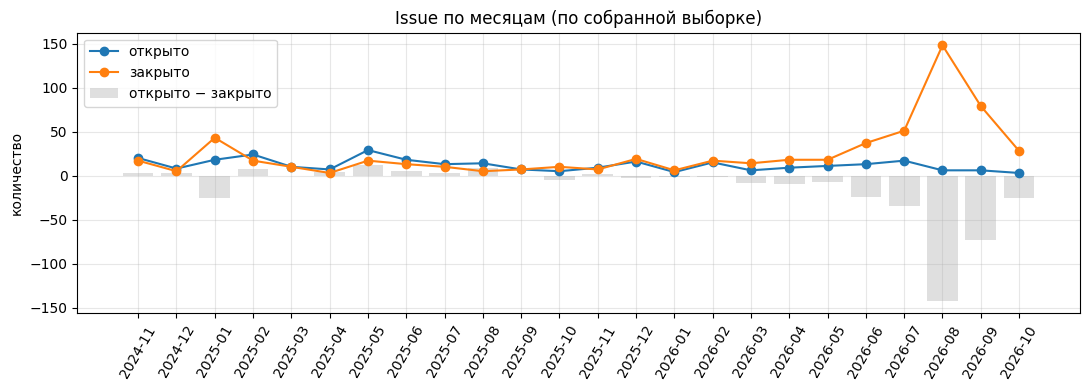

,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
открыто,9,16,4,15,6,9,11,13,17,6,6,3
закрыто,7,19,6,17,14,18,18,37,51,148,79,28
чистый прирост,2,-3,-2,-2,-8,-9,-7,-24,-34,-142,-73,-25


In [105]:
opened = issues.groupby(issues["created_at"].dt.tz_convert(None).dt.to_period("M")).size().rename("открыто")
closed = (issues["closed_at"].dropna().dt.tz_convert(None).dt.to_period("M")
          .value_counts().rename("закрыто"))
monthly = pd.concat([opened, closed], axis=1).fillna(0).astype(int).sort_index()
monthly = monthly[monthly.index >= monthly.index.max() - 23]          # последние 24 месяца
monthly["чистый прирост"] = monthly["открыто"] - monthly["закрыто"]

fig, ax = plt.subplots(figsize=(11, 4))
x = monthly.index.astype(str)
ax.plot(x, monthly["открыто"], marker="o", label="открыто")
ax.plot(x, monthly["закрыто"], marker="o", label="закрыто")
ax.bar(x, monthly["чистый прирост"], alpha=0.25, color="grey", label="открыто − закрыто")
ax.set_title("Issue по месяцам (по собранной выборке)")
ax.set_ylabel("количество")
ax.tick_params(axis="x", rotation=60)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
display(monthly.tail(12).T)

Закрытых issue: 3170, открытых: 138
Время жизни закрытых issue, дни:


,count,mean,std,min,25%,50%,75%,90%,max
lifetime_days,3170.0,461.38,941.32,0.0,0.67,15.08,339.0,1952.58,5508.35


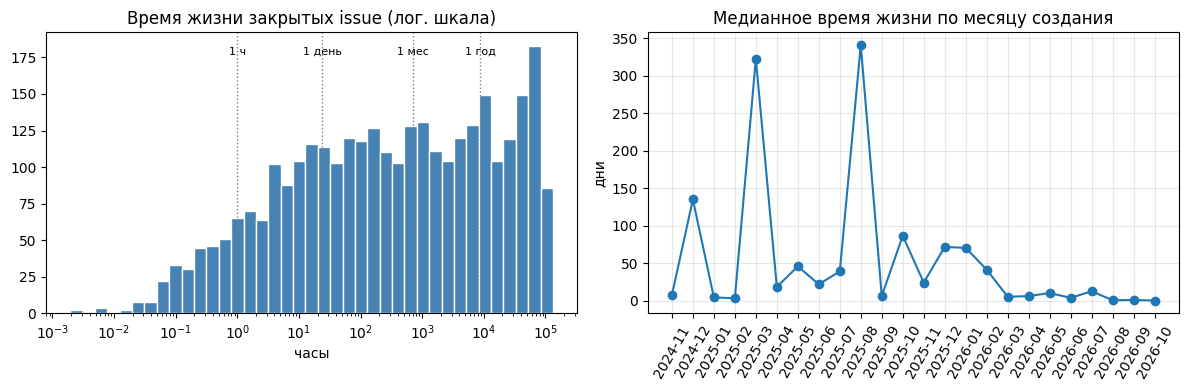

Медиана времени жизни (дни) — автор контрибьютор кода или нет:


,count,median,mean
author_is_contributor,,,
False,2173,5.66,408.79
True,997,65.93,575.98


In [106]:
closed_issues = issues[issues["is_closed"] & issues["lifetime_hours"].gt(0)]
print(f"Закрытых issue: {len(closed_issues)}, открытых: {(~issues['is_closed']).sum()}")
print("Время жизни закрытых issue, дни:")
display(closed_issues["lifetime_days"].describe(percentiles=[.25, .5, .75, .9]).round(2).to_frame().T)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.logspace(np.log10(closed_issues["lifetime_hours"].min()),
                   np.log10(closed_issues["lifetime_hours"].max()), 40)
axes[0].hist(closed_issues["lifetime_hours"], bins=bins, color="steelblue", edgecolor="white")
axes[0].set_xscale("log")
for h, lbl in [(1, "1 ч"), (24, "1 день"), (24 * 30, "1 мес"), (24 * 365, "1 год")]:
    axes[0].axvline(h, color="grey", ls=":", lw=1)
    axes[0].text(h, axes[0].get_ylim()[1] * 0.92, lbl, fontsize=8, ha="center")
axes[0].set_title("Время жизни закрытых issue (лог. шкала)")
axes[0].set_xlabel("часы")

med = (closed_issues.groupby("created_month")["lifetime_days"].median()
       .sort_index().tail(24))
axes[1].plot(med.index, med.values, marker="o")
axes[1].set_title("Медианное время жизни по месяцу создания")
axes[1].set_ylabel("дни")
axes[1].tick_params(axis="x", rotation=60)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Медиана времени жизни (дни) — автор контрибьютор кода или нет:")
display(closed_issues.groupby("author_is_contributor")["lifetime_days"]
        .agg(["count", "median", "mean"]).round(2))

In [107]:
lab = (labels_long.merge(issues[["repo", "issue_id", "is_closed", "lifetime_days"]],
                         on=["repo", "issue_id"], how="inner", validate="m:1"))
by_label = (lab.groupby("label_name")
            .agg(issues=("issue_id", "nunique"), closed_share=("is_closed", "mean"),
                 median_lifetime_days=("lifetime_days", "median"))
            .query("issues >= 10")
            .sort_values("median_lifetime_days", ascending=False)
            .round(2))
print("Метки (≥ 10 issue): доля закрытых и медианное время жизни")
display(by_label.head(15))

Метки (≥ 10 issue): доля закрытых и медианное время жизни


,issues,closed_share,median_lifetime_days
label_name,,,
stale,12,1.00,3848.34
media pipelines,23,0.74,2317.81
S3,14,0.71,2013.30
HTTP/2,11,0.82,1968.83
link extraction,14,1.00,1914.85
logging,47,0.94,1558.48
discuss,178,0.83,1518.88
enhancement,645,0.86,1030.86
performance,20,0.80,886.03


## 11. Выгрузка и метрики для сравнения с no-code

* `data_clean.csv` — итоговая таблица (даты в ISO 8601 UTC);
* `issue_labels.csv` — развёрнутые метки (результат `record_path`);
* `data_raw.jsonl`, `collection_log.csv`, `state.json` — пишутся во время сбора.

In [108]:
issues.to_csv(CLEAN_FILE, index=False, encoding="utf-8", date_format="%Y-%m-%dT%H:%M:%SZ")
labels_long.to_csv(LABELS_FILE, index=False, encoding="utf-8")

for f in (RAW_FILE, CLEAN_FILE, LABELS_FILE, LOG_FILE, STATE_FILE):
    print(f"{f.name:22s} {f.stat().st_size / 1024:9.1f} КБ")

full_log = pd.read_csv(LOG_FILE)
print(f"\nВ журнале {len(full_log)} строк, прогонов: {full_log['run_id'].nunique()}")
display(full_log.tail(5))

data_raw.jsonl           39776.7 КБ
data_clean.csv            1334.5 КБ
issue_labels.csv           133.5 КБ
collection_log.csv          23.9 КБ
state.json                   0.3 КБ

В журнале 93 строк, прогонов: 2


,run_id,ts_utc,endpoint,page,attempt,url,params,status,n_records,duration_s,ratelimit_remaining,ratelimit_reset,wait_s,error
88,20261013T102125Z-63e86b,2026-10-13T10:21:27+00:00,repo:scrapy/scrapy,NaN,1,https://api.github.com/repos/scrapy/scrapy,NaN,200,NaN,0.422,4878,1791889748,NaN,NaN
89,20261013T102125Z-63e86b,2026-10-13T10:21:28+00:00,contributors:scrapy/scrapy,0.0,1,https://api.github.com/repos/scrapy/scrapy/contributors?...,"{""per_page"": 100}",200,100.0,0.406,4877,1791889748,NaN,NaN
90,20261013T102125Z-63e86b,2026-10-13T10:21:29+00:00,contributors:scrapy/scrapy,1.0,1,https://api.github.com/repositories/529502/contributors?...,NaN,200,100.0,0.453,4876,1791889748,NaN,NaN
91,20261013T102125Z-63e86b,2026-10-13T10:21:30+00:00,contributors:scrapy/scrapy,2.0,1,https://api.github.com/repositories/529502/contributors?...,NaN,200,100.0,0.406,4875,1791889748,NaN,NaN
92,20261013T102125Z-63e86b,2026-10-13T10:21:31+00:00,contributors:scrapy/scrapy,3.0,1,https://api.github.com/repositories/529502/contributors?...,NaN,200,74.0,0.469,4874,1791889748,NaN,NaN


In [109]:
issue_log1 = log1[log1["endpoint"].str.startswith("issues")]
metrics = pd.DataFrame([
    ("Время разработки, мин",              "270"),
    ("Число собранных записей (issue без PR)", len(issues)),
    ("Объектов из API за прогон 1 (с PR)", int(summary1.loc[summary1["endpoint"].str.startswith("issues"), "records"].sum())),
    ("Страниц issues за прогон 1",          int(issue_log1.loc[issue_log1["status"] == 200, "page"].nunique())),
    ("HTTP-запросов за прогон 1",           len(log1)),
    ("Время выполнения прогона 1, с",      round(elapsed1, 1)),
    ("Время инкрементального прогона, с",  round(elapsed2, 1)),
    ("Поддержка пагинации",                "Link rel=next, предохранители max_pages / max_records / пустая страница"),
    ("Обработка ошибок и повторов",        "429/5xx/таймаут: backoff+jitter, Retry-After, X-RateLimit-Reset; 4xx без повторов; журнал попыток"),
    ("Воспроизводимость",                  "Git: блокнот + requirements.txt + README; состояние в state.json"),
    ("Стоимость при 100 прогонах/мес",     "0 ₽ (локально / GitHub Actions free tier); ~16 запросов к API на прогон"),
], columns=["Критерий", "Python"])
display(metrics)

,Критерий,Python
0,"Время разработки, мин",270
1,Число собранных записей (issue без PR),3308
2,Объектов из API за прогон 1 (с PR),8148
3,Страниц issues за прогон 1,82
4,HTTP-запросов за прогон 1,87
5,"Время выполнения прогона 1, с",92.1
6,"Время инкрементального прогона, с",5.5
7,Поддержка пагинации,"Link rel=next, предохранители max_pages / max_records / ..."
8,Обработка ошибок и повторов,"429/5xx/таймаут: backoff+jitter, Retry-After, X-RateLimi..."
9,Воспроизводимость,Git: блокнот + requirements.txt + README; состояние в st...
